# 📊 Data Exploration - SAR Processing System

Welcome to Phase 1 of the Financial Services Agentic AI Project!

In this notebook, you'll explore the financial data that forms the foundation of our SAR (Suspicious Activity Report) processing system. Understanding this data is crucial for designing effective Pydantic schemas and building your AI agents.

## 🎯 Learning Objectives
- Understand the structure of customer, account, and transaction data
- Identify relationships between different data entities
- Recognize patterns that might indicate suspicious activity
- Prepare for designing Pydantic schemas in `foundation_sar.py`

## 📋 Business Context
Financial institutions are required by law to monitor customer transactions and report suspicious activities to authorities. This process involves:
- **Customer Due Diligence**: Understanding who your customers are
- **Transaction Monitoring**: Watching for unusual patterns
- **Risk Assessment**: Evaluating the likelihood of financial crimes
- **Regulatory Reporting**: Filing SARs when required

## 🚀 Setup and Data Loading

In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta
import warnings
warnings.filterwarnings('ignore')

# Set display options
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 10)

print("📚 Libraries loaded successfully!")
print("🎯 Ready to explore financial data for SAR processing")

📚 Libraries loaded successfully!
🎯 Ready to explore financial data for SAR processing


In [2]:
# Load the three main data files
customers_df = pd.read_csv('../data/customers.csv')
accounts_df = pd.read_csv('../data/accounts.csv')
transactions_df = pd.read_csv('../data/transactions.csv')

print("📊 Data loaded successfully!")
print(f"👥 Customers: {len(customers_df):,} records")
print(f"🏦 Accounts: {len(accounts_df):,} records")
print(f"💳 Transactions: {len(transactions_df):,} records")

📊 Data loaded successfully!
👥 Customers: 150 records
🏦 Accounts: 178 records
💳 Transactions: 4,268 records


## 👥 Customer Data Analysis

In [3]:
# Explore customer data structure
print("📋 Customer Data Overview")
print("=" * 50)
print(f"Shape: {customers_df.shape}")
print(f"Columns: {list(customers_df.columns)}")
print("\n📊 First few records:")
customers_df.head()

📋 Customer Data Overview
Shape: (150, 10)
Columns: ['customer_id', 'name', 'date_of_birth', 'ssn_last_4', 'address', 'phone', 'customer_since', 'risk_rating', 'occupation', 'annual_income']

📊 First few records:


,customer_id,name,date_of_birth,ssn_last_4,address,phone,customer_since,risk_rating,occupation,annual_income
0,CUST_0001,Allison Hill,1958-08-25,2679,"600 Jeffery Parkways, New Jamesside, MT 29394",394.802.6542x351,2016-06-14,Low,Local government officer,48815
1,CUST_0002,Renee Blair,1978-05-14,7201,"959 Janet Cape Apt. 413, South Joshuastad, GA ...",(534)719-2832x764,2023-03-03,Low,Banker,72005
2,CUST_0003,Andrew Stewart,1961-06-14,4456,"PSC 9537, Box 6724, APO AE 32826",001-388-249-6965x3287,2023-05-02,Low,"Designer, ceramics/pottery",48664
3,CUST_0004,Rebecca Henderson,1948-08-02,7252,"480 Erin Plain Suite 514, Mooretown, VA 94830",282-781-4893x252,2019-12-25,Low,Clinical research associate,54285
4,CUST_0005,Sherry Decker,1963-12-16,1949,"71822 Arroyo Expressway, Allisonchester, IL 71187",001-534-565-7871x33150,2015-08-25,Low,Barrister's clerk,87356


In [4]:
# Analyze customer data types and missing values
print("🔍 Customer Data Quality Analysis")
print("=" * 50)
print("\n📊 Data Types:")
print(customers_df.dtypes)
print("\n❓ Missing Values:")
print(customers_df.isnull().sum())
print("\n📈 Basic Statistics:")
customers_df.describe(include='all')

🔍 Customer Data Quality Analysis

📊 Data Types:
customer_id         str
name                str
date_of_birth       str
ssn_last_4        int64
address             str
phone               str
customer_since      str
risk_rating         str
occupation          str
annual_income     int64
dtype: object

❓ Missing Values:
customer_id       0
name              0
date_of_birth     0
ssn_last_4        0
address           0
phone             0
customer_since    0
risk_rating       0
occupation        0
annual_income     0
dtype: int64

📈 Basic Statistics:


,customer_id,name,date_of_birth,ssn_last_4,address,phone,customer_since,risk_rating,occupation,annual_income
count,150,150,150,150.000000,150,150,150,150,150,150.000000
unique,150,150,149,NaN,150,150,148,3,130,NaN
top,CUST_0001,Allison Hill,1970-10-30,NaN,"600 Jeffery Parkways, New Jamesside, MT 29394",394.802.6542x351,2019-04-25,Low,"Designer, ceramics/pottery",NaN
freq,1,1,2,NaN,1,1,2,118,3,NaN
mean,NaN,NaN,NaN,5722.413333,NaN,NaN,NaN,NaN,NaN,84477.826667
...,...,...,...,...,...,...,...,...,...,...
min,NaN,NaN,NaN,1090.000000,NaN,NaN,NaN,NaN,NaN,30284.000000
25%,NaN,NaN,NaN,3494.000000,NaN,NaN,NaN,NaN,NaN,52581.250000
50%,NaN,NaN,NaN,5878.500000,NaN,NaN,NaN,NaN,NaN,71810.000000
75%,NaN,NaN,NaN,7849.750000,NaN,NaN,NaN,NaN,NaN,91118.250000


⚠️ Customer Risk Rating Analysis
risk_rating
Low       118
Medium     25
High        7
Name: count, dtype: int64


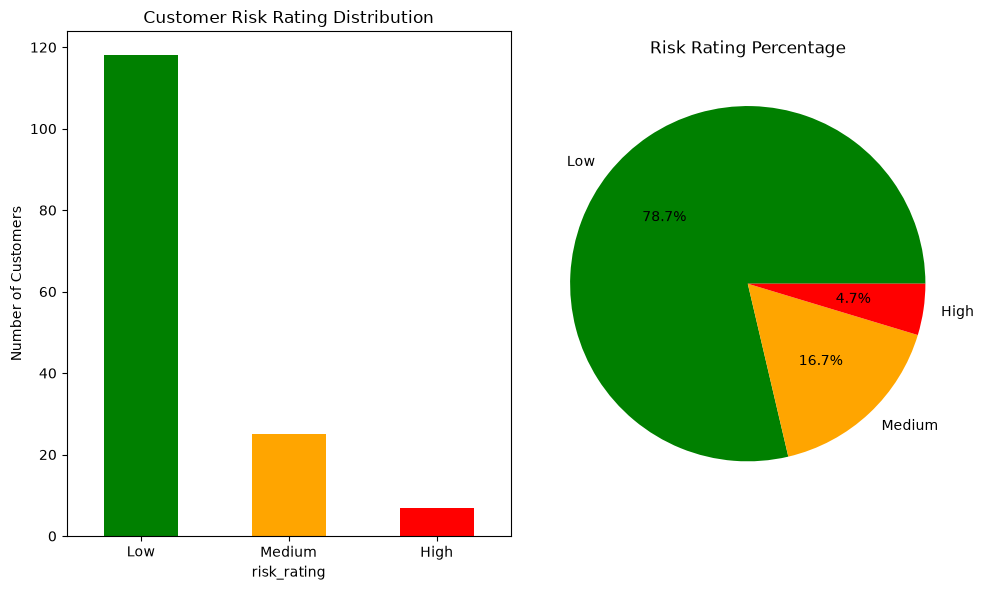


💡 Key Insights:
• 7 customers (4.7%) are High Risk
• These high-risk customers require enhanced monitoring


In [5]:
# Analyze risk ratings distribution
print("⚠️ Customer Risk Rating Analysis")
print("=" * 50)
risk_counts = customers_df['risk_rating'].value_counts()
print(risk_counts)

# Visualize risk distribution
plt.figure(figsize=(10, 6))
plt.subplot(1, 2, 1)
risk_counts.plot(kind='bar', color=['green', 'orange', 'red'])
plt.title('Customer Risk Rating Distribution')
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)

plt.subplot(1, 2, 2)
plt.pie(risk_counts.values, labels=risk_counts.index, autopct='%1.1f%%', 
        colors=['green', 'orange', 'red'])
plt.title('Risk Rating Percentage')

plt.tight_layout()
plt.show()

print(f"\n💡 Key Insights:")
print(f"• {risk_counts['High']} customers ({risk_counts['High']/len(customers_df)*100:.1f}%) are High Risk")
print(f"• These high-risk customers require enhanced monitoring")

### 📝 Schema Design: CustomerData

Implemented in `src/foundation_sar.py`. Decisions taken from the exploration above:

**Required vs optional**
- Identity and KYC fields (`customer_id`, `name`, `date_of_birth`, `ssn_last_4`, `address`, `customer_since`, `risk_rating`) are **required**: a SAR cannot identify its subject without them.
- `phone`, `occupation`, `annual_income` are **optional** (`None` by default). This extract has no gaps, but upstream KYC data is often incomplete, and a missing phone number should not block a case.

**Validation rules**
- Dates must be real calendar dates in `YYYY-MM-DD` format (`1980-02-30` is rejected), and `customer_since` cannot precede `date_of_birth`.
- `risk_rating` is a `Literal['Low', 'Medium', 'High']`. Case variants such as `'high'` are normalised before validation.
- `annual_income` must be non-negative.
- Empty CSV cells (pandas `NaN`) are converted to `None` before validation, so `DataFrame.to_dict('records')` can be passed in directly.

**SSN handling**
- Only the last 4 digits are ever stored, as a string matching `^\d{4}$`.
- pandas reads this column as `int64` (see the dtypes above), so a pre-validator converts it back to a string and zero-pads it, so values like `0123` are not mangled.
- Data minimisation: the agents in Phase 2 have no need for the SSN fragment, so it should be left out of LLM prompts.

## 🏦 Account Data Analysis

In [6]:
# Explore account data structure
print("📋 Account Data Overview")
print("=" * 50)
print(f"Shape: {accounts_df.shape}")
print(f"Columns: {list(accounts_df.columns)}")
print("\n📊 First few records:")
accounts_df.head()

📋 Account Data Overview
Shape: (178, 7)
Columns: ['account_id', 'customer_id', 'account_type', 'opening_date', 'current_balance', 'average_monthly_balance', 'status']

📊 First few records:


,account_id,customer_id,account_type,opening_date,current_balance,average_monthly_balance,status
0,CUST_0001_ACC_1,CUST_0001,Checking,2020-05-06,51690.75,0.00,Closed
1,CUST_0002_ACC_1,CUST_0002,Money_Market,2023-12-03,92121.66,172242.96,Active
2,CUST_0003_ACC_1,CUST_0003,Savings,2024-09-11,55458.06,127691.16,Active
3,CUST_0004_ACC_1,CUST_0004,Savings,2022-07-01,72296.19,0.00,Closed
4,CUST_0005_ACC_1,CUST_0005,Money_Market,2016-12-15,95327.95,0.00,Closed


💰 Account Analysis

🏦 Account Types:
account_type
Money_Market         48
Checking             44
Business_Checking    44
Savings              42
Name: count, dtype: int64

💵 Balance Statistics:
       current_balance  average_monthly_balance
count       178.000000               178.000000
mean      53623.018820            112713.608202
std       28276.544824             88984.275551
min        1008.470000                 0.000000
25%       30692.320000             83495.732500
50%       56865.055000            120237.815000
75%       77785.737500            151401.497500
max       99932.150000            860095.530000


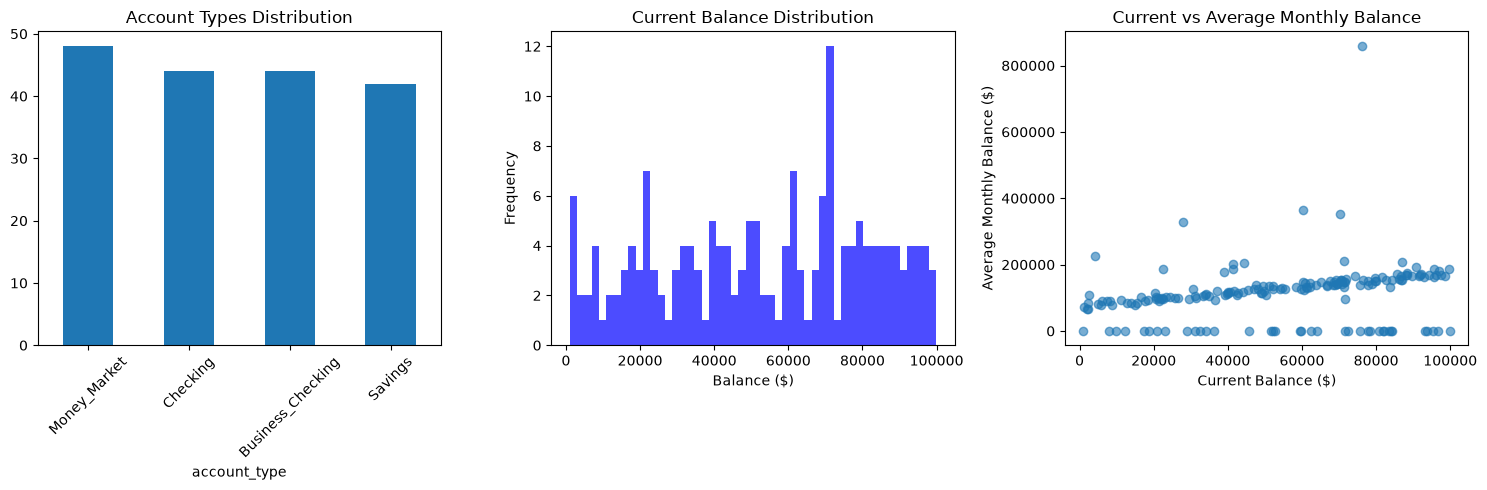

In [7]:
# Analyze account types and balances
print("💰 Account Analysis")
print("=" * 50)

# Account types
print("\n🏦 Account Types:")
account_types = accounts_df['account_type'].value_counts()
print(account_types)

# Balance analysis
print("\n💵 Balance Statistics:")
print(accounts_df[['current_balance', 'average_monthly_balance']].describe())

# Visualize balance distributions
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
account_types.plot(kind='bar')
plt.title('Account Types Distribution')
plt.xticks(rotation=45)

plt.subplot(1, 3, 2)
plt.hist(accounts_df['current_balance'], bins=50, alpha=0.7, color='blue')
plt.title('Current Balance Distribution')
plt.xlabel('Balance ($)')
plt.ylabel('Frequency')

plt.subplot(1, 3, 3)
plt.scatter(accounts_df['current_balance'], accounts_df['average_monthly_balance'], alpha=0.6)
plt.title('Current vs Average Monthly Balance')
plt.xlabel('Current Balance ($)')
plt.ylabel('Average Monthly Balance ($)')

plt.tight_layout()
plt.show()

🔗 Customer-Account Relationships

📊 Accounts per Customer:
1    130
2     12
3      8
Name: count, dtype: int64

👥 Customers with multiple accounts: 20
📈 Max accounts per customer: 3


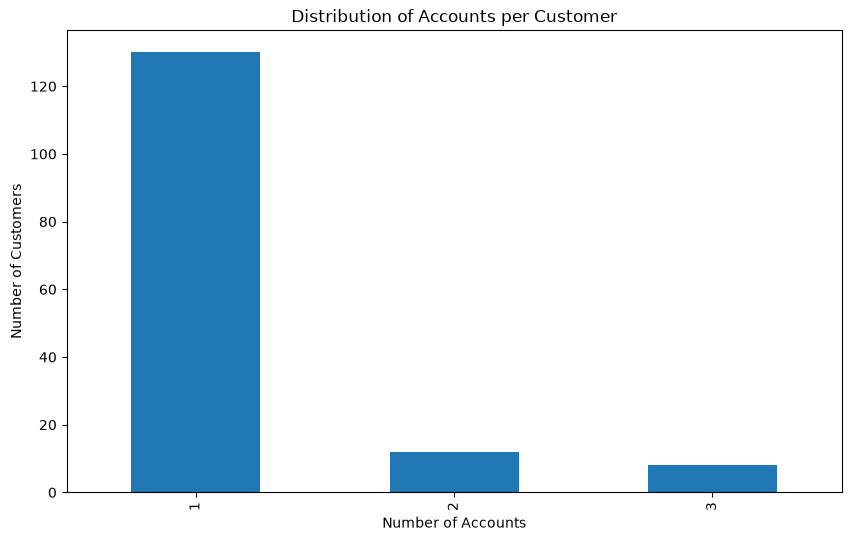

In [8]:
# Analyze customer-account relationships
print("🔗 Customer-Account Relationships")
print("=" * 50)

# How many accounts per customer?
accounts_per_customer = accounts_df.groupby('customer_id').size()
print("\n📊 Accounts per Customer:")
print(accounts_per_customer.value_counts().sort_index())

# Customers with multiple accounts
multi_account_customers = accounts_per_customer[accounts_per_customer > 1]
print(f"\n👥 Customers with multiple accounts: {len(multi_account_customers)}")
print(f"📈 Max accounts per customer: {accounts_per_customer.max()}")

# Visualize accounts per customer
plt.figure(figsize=(10, 6))
accounts_per_customer.value_counts().sort_index().plot(kind='bar')
plt.title('Distribution of Accounts per Customer')
plt.xlabel('Number of Accounts')
plt.ylabel('Number of Customers')
plt.show()

### 📝 Schema Design: AccountData

- **Linking to customers:** each account carries `customer_id`. `CaseData` enforces that every account in a case belongs to the case customer, and `DataLoader` filters the full account extract down to that customer.
- **Balances:** `float` fields that must be finite (`NaN`/`inf` rejected). `current_balance` may be negative so that overdrafts are representable, even though this extract has none. Closed accounts report an `average_monthly_balance` of `0.00`, which is valid.
- **Status:** kept as a validated non-empty string rather than a closed `Literal`. The extract only contains `Active`/`Closed`, but `Suspended` and others are documented upstream values, and an unexpected status should not break ingestion. Activity on a *closed* account is itself a risk signal (quantified in the data quality section below).
- **Dates:** `opening_date` uses the same strict `YYYY-MM-DD` validation as the customer dates.

## 💳 Transaction Data Analysis

In [9]:
# Explore transaction data structure
print("📋 Transaction Data Overview")
print("=" * 50)
print(f"Shape: {transactions_df.shape}")
print(f"Columns: {list(transactions_df.columns)}")
print("\n📊 First few records:")
transactions_df.head()

📋 Transaction Data Overview
Shape: (4268, 9)
Columns: ['transaction_id', 'account_id', 'transaction_date', 'transaction_type', 'amount', 'description', 'counterparty', 'location', 'method']

📊 First few records:


,transaction_id,account_id,transaction_date,transaction_type,amount,description,counterparty,location,method
0,TXN_B24455F3,CUST_0002_ACC_1,2025-02-18,Online_Transfer,1615.06,Credit card payment,NaN,Branch_Westside_Plaza,ATM
1,TXN_0A18BAD4,CUST_0002_ACC_1,2025-02-22,Check_Deposit,2564.42,Gas station,NaN,NaN,Electronic
2,TXN_F3A18FF3,CUST_0002_ACC_1,2025-07-31,ACH_Credit,3192.71,Utility bill,NaN,NaN,Online
3,TXN_0003D37D,CUST_0002_ACC_1,2025-03-04,Check_Deposit,4664.01,Mortgage payment,NaN,Branch_Downtown_Main,Branch
4,TXN_4FEA8992,CUST_0002_ACC_1,2025-03-26,ACH_Credit,1426.10,Salary deposit,NaN,Branch_University_District,ATM


In [10]:
# Convert transaction_date to datetime for analysis
transactions_df['transaction_date'] = pd.to_datetime(transactions_df['transaction_date'])

print("💰 Transaction Analysis")
print("=" * 50)

# Transaction types
print("\n📊 Transaction Types:")
txn_types = transactions_df['transaction_type'].value_counts()
print(txn_types)

# Transaction methods
print("\n💳 Transaction Methods:")
txn_methods = transactions_df['method'].value_counts()
print(txn_methods)

# Amount statistics
print("\n💵 Transaction Amount Statistics:")
print(transactions_df['amount'].describe())

💰 Transaction Analysis

📊 Transaction Types:
transaction_type
Online_Transfer         563
ACH_Debit               553
ACH_Credit              544
ATM_Withdrawal          534
Wire_Transfer           508
                       ... 
Debit_Purchase          490
Cash_Deposit             50
Wire_Transfer_Debit      17
Cash_Withdrawal           5
Wire_Transfer_Credit      4
Name: count, Length: 12, dtype: int64

💳 Transaction Methods:
method
Electronic    910
ATM           894
Online        808
Mobile        806
Branch        804
Cash           25
Wire           21
Name: count, dtype: int64

💵 Transaction Amount Statistics:
count     4268.000000
mean      2668.532800
std       3083.916636
min         11.670000
25%       1256.260000
50%       2485.715000
75%       3756.482500
max      98090.160000
Name: amount, dtype: float64


In [11]:
# Analyze transaction patterns for suspicious activity indicators
print("🚨 Suspicious Activity Pattern Analysis")
print("=" * 50)

# Large transactions (potential money laundering)
large_transactions = transactions_df[transactions_df['amount'] >= 100000]
print(f"\n💰 Large transactions (≥$100k): {len(large_transactions)}")

# Transactions just under $10k (potential structuring)
structuring_range = transactions_df[
    (transactions_df['amount'] >= 9000) & 
    (transactions_df['amount'] < 10000)
]
print(f"🔄 Potential structuring ($9k-$10k): {len(structuring_range)}")

# High-frequency customers (many transactions)
txn_per_account = transactions_df.groupby('account_id').size()
high_frequency_accounts = txn_per_account[txn_per_account >= 50]
print(f"📈 High-frequency accounts (≥50 txns): {len(high_frequency_accounts)}")

# Wire transfers (higher risk method)
wire_transfers = transactions_df[transactions_df['method'] == 'Wire']
print(f"🌐 Wire transfers: {len(wire_transfers)}")

print(f"\n⚠️ Potential Suspicious Indicators:")
print(f"• {len(large_transactions)} large transactions requiring enhanced scrutiny")
print(f"• {len(structuring_range)} transactions in structuring range")
print(f"• {len(high_frequency_accounts)} accounts with high transaction frequency")
print(f"• {len(wire_transfers)} wire transfers (higher risk method)")

🚨 Suspicious Activity Pattern Analysis

💰 Large transactions (≥$100k): 0
🔄 Potential structuring ($9k-$10k): 18
📈 High-frequency accounts (≥50 txns): 7
🌐 Wire transfers: 21

⚠️ Potential Suspicious Indicators:
• 0 large transactions requiring enhanced scrutiny
• 18 transactions in structuring range
• 7 accounts with high transaction frequency
• 21 wire transfers (higher risk method)


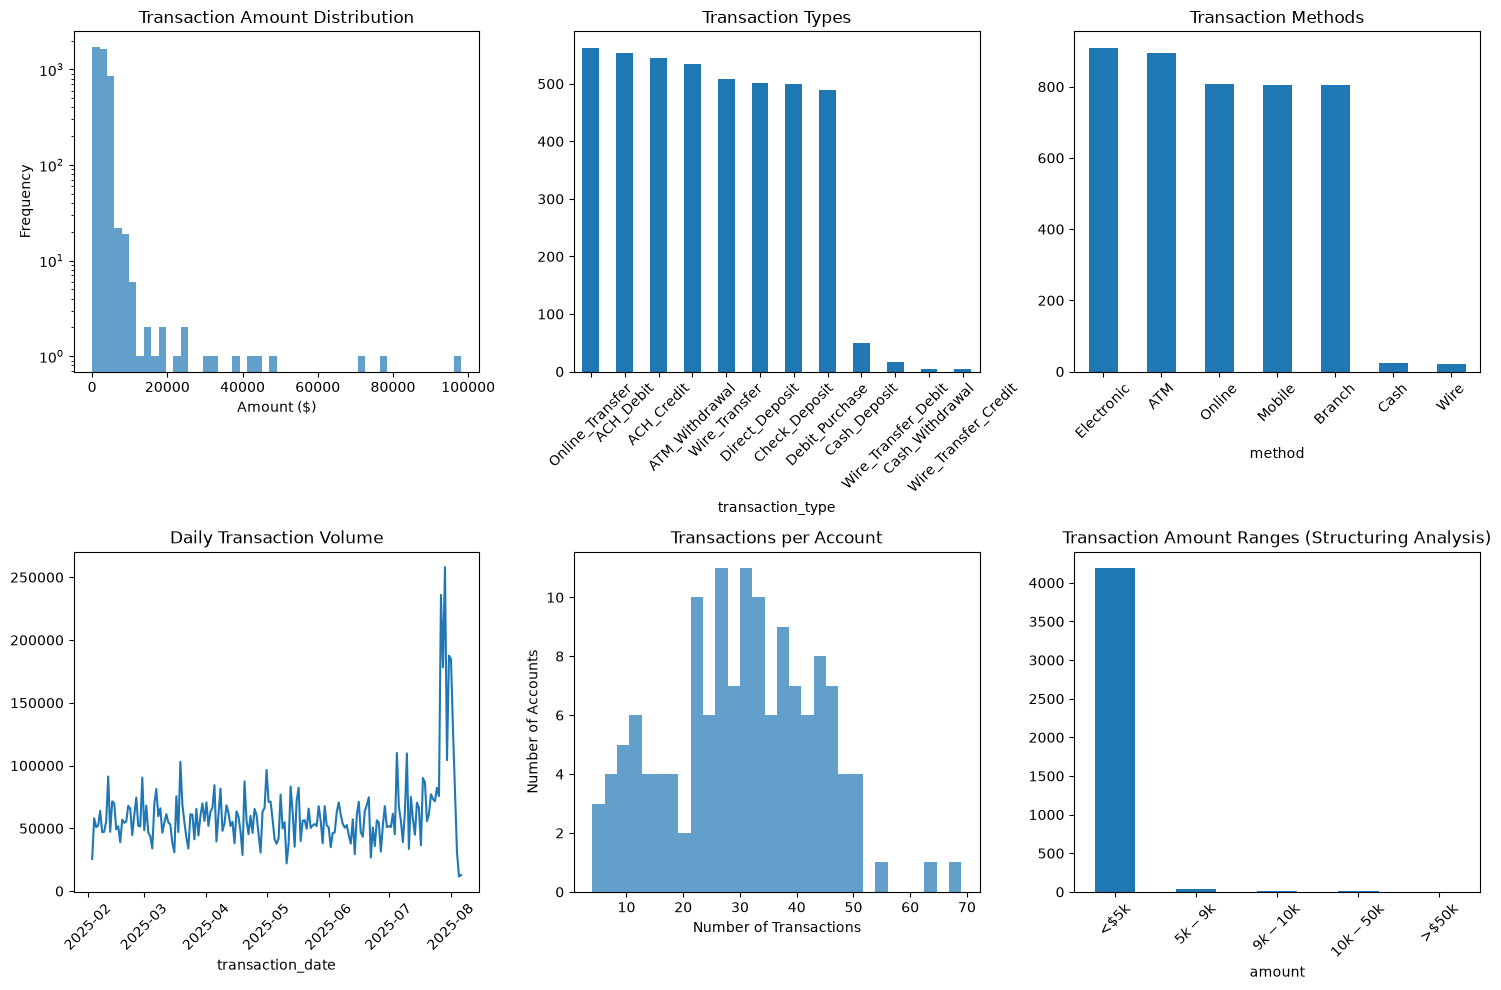

In [12]:
# Visualize transaction patterns
plt.figure(figsize=(15, 10))

# Transaction amounts distribution
plt.subplot(2, 3, 1)
plt.hist(transactions_df['amount'], bins=50, alpha=0.7)
plt.title('Transaction Amount Distribution')
plt.xlabel('Amount ($)')
plt.ylabel('Frequency')
plt.yscale('log')  # Log scale due to wide range

# Transaction types
plt.subplot(2, 3, 2)
txn_types.plot(kind='bar')
plt.title('Transaction Types')
plt.xticks(rotation=45)

# Transaction methods
plt.subplot(2, 3, 3)
txn_methods.plot(kind='bar')
plt.title('Transaction Methods')
plt.xticks(rotation=45)

# Daily transaction volume
plt.subplot(2, 3, 4)
daily_volume = transactions_df.groupby(transactions_df['transaction_date'].dt.date)['amount'].sum()
daily_volume.plot()
plt.title('Daily Transaction Volume')
plt.xticks(rotation=45)

# Transaction count per account
plt.subplot(2, 3, 5)
plt.hist(txn_per_account, bins=30, alpha=0.7)
plt.title('Transactions per Account')
plt.xlabel('Number of Transactions')
plt.ylabel('Number of Accounts')

# Structuring analysis
plt.subplot(2, 3, 6)
amount_ranges = pd.cut(transactions_df['amount'], 
                      bins=[0, 5000, 9000, 10000, 50000, float('inf')],
                      labels=['<$5k', '$5k-$9k', '$9k-$10k', '$10k-$50k', '>$50k'])
amount_ranges.value_counts().plot(kind='bar')
plt.title('Transaction Amount Ranges (Structuring Analysis)')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### 📝 Schema Design: TransactionData & CaseData

**TransactionData**
- `counterparty` and `location` are **optional**: most rows leave them empty (see the missing-value counts), so `NaN` becomes `None`.
- `amount` must be finite and **non-zero**. Negative values are allowed for debits, but note that this extract records *every* amount as positive. Direction comes from `transaction_type` (e.g. `Wire_Transfer_Debit`), not from the sign.
- `transaction_date` is validated as `YYYY-MM-DD`.

**CaseData**: the unit of work handed to the agents
- `transactions` cannot be empty, because a case needs activity to analyse.
- All accounts must belong to the case customer, and when account records are present every transaction must post to one of them. Cases built from a transaction-only alert (no account records) are allowed with an empty `accounts` list.
- Transaction IDs must be unique, and `case_created_at` must be an ISO-8601 timestamp.
- `data_sources` records which extract each entity came from, for the audit trail.

## 🔗 Data Relationships Analysis

In [13]:
# Analyze the complete data relationship chain
print("🔗 Complete Data Relationship Analysis")
print("=" * 50)

# Join all datasets to understand relationships
# First join accounts with customers
customer_accounts = accounts_df.merge(customers_df, on='customer_id', how='left')

# Then join with transactions
full_data = transactions_df.merge(customer_accounts, on='account_id', how='left')

print(f"\n📊 Combined dataset shape: {full_data.shape}")
print(f"✅ Successful joins: {len(full_data[full_data['customer_id'].notna()])} / {len(full_data)}")

# Check for any orphaned records
orphaned_transactions = full_data[full_data['customer_id'].isna()]
if len(orphaned_transactions) > 0:
    print(f"⚠️ Found {len(orphaned_transactions)} orphaned transactions (no matching account/customer)")
else:
    print("✅ All transactions have valid account and customer relationships")

🔗 Complete Data Relationship Analysis

📊 Combined dataset shape: (4268, 24)
✅ Successful joins: 4268 / 4268
✅ All transactions have valid account and customer relationships


In [14]:
# Analyze high-risk customer activity
print("⚠️ High-Risk Customer Activity Analysis")
print("=" * 50)

# Filter for high-risk customers
high_risk_data = full_data[full_data['risk_rating'] == 'High']

print(f"\n📊 High-risk customer transactions: {len(high_risk_data)}")
print(f"💰 Total high-risk transaction volume: ${high_risk_data['amount'].sum():,.2f}")
print(f"📈 Average transaction amount: ${high_risk_data['amount'].mean():,.2f}")

# High-risk customers with large transactions
high_risk_large = high_risk_data[high_risk_data['amount'] >= 50000]
print(f"\n🚨 High-risk customers with large transactions (≥$50k): {len(high_risk_large)}")

if len(high_risk_large) > 0:
    print("\n🔍 Sample high-risk large transactions:")
    print(high_risk_large[['name', 'amount', 'transaction_type', 'method', 'transaction_date']].head())

⚠️ High-Risk Customer Activity Analysis

📊 High-risk customer transactions: 407
💰 Total high-risk transaction volume: $1,172,007.73
📈 Average transaction amount: $2,879.63

🚨 High-risk customers with large transactions (≥$50k): 1

🔍 Sample high-risk large transactions:
                      name    amount      transaction_type method  \
4112  Jacqueline Rodriguez  76517.25  Wire_Transfer_Credit   Wire   

     transaction_date  
4112       2025-07-29  


In [15]:
# Identify potential cases for SAR processing
print("🎯 Potential SAR Cases Identification")
print("=" * 50)

# Define criteria for suspicious cases
def identify_suspicious_cases(df):
    suspicious_criteria = {
        'high_risk_customers': df['risk_rating'] == 'High',
        'large_transactions': df['amount'] >= 100000,
        'high_frequency': df.groupby('customer_id')['transaction_id'].transform('count') >= 50,
        'wire_transfers': df['method'] == 'Wire'
    }
    
    # Apply any of the criteria
    suspicious_mask = (
        suspicious_criteria['high_risk_customers'] |
        suspicious_criteria['large_transactions'] |
        suspicious_criteria['high_frequency'] |
        suspicious_criteria['wire_transfers']
    )
    
    return df[suspicious_mask], suspicious_criteria

suspicious_data, criteria = identify_suspicious_cases(full_data)

print(f"\n📊 Suspicious transactions identified: {len(suspicious_data)}")
print(f"👥 Unique customers involved: {suspicious_data['customer_id'].nunique()}")

# Break down by criteria
print("\n🔍 Breakdown by criteria:")
for criterion, mask in criteria.items():
    count = full_data[mask]['customer_id'].nunique()
    print(f"• {criterion.replace('_', ' ').title()}: {count} customers")

# Top customers by transaction volume
customer_volumes = suspicious_data.groupby(['customer_id', 'name'])['amount'].agg(['sum', 'count']).reset_index()
customer_volumes = customer_volumes.sort_values('sum', ascending=False)

print("\n💰 Top 5 customers by suspicious transaction volume:")
print(customer_volumes.head())

🎯 Potential SAR Cases Identification

📊 Suspicious transactions identified: 1482
👥 Unique customers involved: 25

🔍 Breakdown by criteria:
• High Risk Customers: 7 customers
• Large Transactions: 0 customers
• High Frequency: 20 customers
• Wire Transfers: 4 customers

💰 Top 5 customers by suspicious transaction volume:
   customer_id                  name        sum  count
16   CUST_0111  Jacqueline Rodriguez  386834.91    121
7    CUST_0062       Michael Stanley  380633.78     90
6    CUST_0057         Cindy Clayton  286342.62    101
5    CUST_0053           Tracy Lewis  274025.18     94
17   CUST_0118      Patrick Williams  222070.26     79


## 🕵️ Deep Dive: Detecting the Main Suspicious Typologies

The screening above is deliberately coarse. The `≥$100k` rule catches nothing (the largest transaction is about $98k), while "any wire" or "≥50 transactions" flag a broad slice of normal customers. Below are targeted rules for the typologies the agents must classify, using the relevant regulatory thresholds:

| Rule | Typology | Logic |
|------|----------|-------|
| **Structuring** | Structuring | 3+ cash deposits between \$9,000 and the \$10,000 CTR threshold |
| **Rapid movement** | Money laundering (layering) | Incoming wire fanned out as 3+ outgoing wires within 3 days |
| **Cash velocity** | Money laundering / structuring | Cash/ATM activity at 2+ branches within 3 days totalling ≥ \$10,000 |
| **Large cash** | CTR-reportable / possible fraud | Single cash transactions ≥ \$10,000 |

In [16]:
# Rule-based detection of the main AML typologies in the dataset
print("🕵️ Typology Detection Rules")
print("=" * 50)

CTR_THRESHOLD = 10_000  # Currency Transaction Report threshold (31 CFR 1010.311)
cash_channel = full_data[full_data['method'].isin(['Cash', 'ATM'])]

# 1. Structuring: repeated cash deposits just under the CTR threshold
near_threshold = cash_channel[
    (cash_channel['transaction_type'] == 'Cash_Deposit') &
    (cash_channel['amount'] >= 9_000) &
    (cash_channel['amount'] < CTR_THRESHOLD)
]
structuring = near_threshold.groupby(['customer_id', 'name']).agg(
    deposits=('amount', 'size'),
    total=('amount', 'sum'),
    branches=('location', 'nunique'),
    days_span=('transaction_date', lambda d: (d.max() - d.min()).days)
)
structuring = structuring[structuring['deposits'] >= 3]

# 2. Rapid movement: a large incoming wire fanned out to many counterparties within days
wires_in = full_data[full_data['transaction_type'] == 'Wire_Transfer_Credit'].groupby(['customer_id', 'name']).agg(
    wired_in=('amount', 'sum'),
    first_in=('transaction_date', 'min')
)
wires_out = full_data[full_data['transaction_type'] == 'Wire_Transfer_Debit'].groupby(['customer_id', 'name']).agg(
    outgoing_wires=('amount', 'size'),
    wired_out=('amount', 'sum'),
    counterparties=('counterparty', 'nunique'),
    last_out=('transaction_date', 'max')
)
rapid_movement = wires_in.join(wires_out, how='inner')
rapid_movement['pass_through_pct'] = rapid_movement['wired_out'] / rapid_movement['wired_in'] * 100
rapid_movement['days_span'] = (rapid_movement['last_out'] - rapid_movement['first_in']).dt.days
rapid_movement = rapid_movement[(rapid_movement['outgoing_wires'] >= 3) & (rapid_movement['days_span'] <= 3)]
rapid_movement = rapid_movement.drop(columns=['first_in', 'last_out'])

# 3. Cash velocity: cash/ATM activity spread across branches in a short window
def has_cash_velocity(txns, window_days=3, min_branches=2, min_total=CTR_THRESHOLD):
    """True if any window of `window_days` has activity at `min_branches`+ branches totalling `min_total`+."""
    txns = txns.dropna(subset=['location']).sort_values('transaction_date')
    for start in txns['transaction_date']:
        window = txns[(txns['transaction_date'] >= start) &
                      (txns['transaction_date'] < start + pd.Timedelta(days=window_days))]
        if window['location'].nunique() >= min_branches and window['amount'].sum() >= min_total:
            return True
    return False

structuring_ids = set(structuring.index.get_level_values('customer_id'))
velocity_ids = [cid for cid, txns in cash_channel.groupby('customer_id')
                if has_cash_velocity(txns) and cid not in structuring_ids]  # structuring cases also trip this rule
cash_velocity = cash_channel[cash_channel['customer_id'].isin(velocity_ids)].groupby(['customer_id', 'name']).agg(
    cash_txns=('amount', 'size'),
    branches=('location', 'nunique'),
    total=('amount', 'sum')
)

# 4. Large cash: individual CTR-reportable cash transactions
large_cash = cash_channel[cash_channel['amount'] >= CTR_THRESHOLD].groupby(['customer_id', 'name']).agg(
    large_cash_txns=('amount', 'size'),
    total=('amount', 'sum'),
    max_txn=('amount', 'max')
)

typology_results = {
    'Structuring': structuring,
    'Rapid Movement': rapid_movement,
    'Cash Velocity': cash_velocity,
    'Large Cash': large_cash
}
for rule_name, result in typology_results.items():
    print(f"\n🚩 {rule_name}: {len(result)} customers")
    print(result.round(2).to_string())

typology_flags = {rule: set(result.index.get_level_values('customer_id'))
                  for rule, result in typology_results.items()}
flagged_customers = set().union(*typology_flags.values())
print(f"\n🎯 Total customers flagged by targeted rules: {len(flagged_customers)}")

🕵️ Typology Detection Rules

🚩 Structuring: 4 customers
                            deposits     total  branches  days_span
customer_id name                                                   
CUST_0018   Tanya Johnston         4  37536.45         3          3
CUST_0053   Tracy Lewis            7  67569.06         5          6
CUST_0090   Brandon Reyes          4  38107.63         3          3
CUST_0137   Regina Ramos           3  28118.47         2          2

🚩 Rapid Movement: 4 customers
                                  wired_in  outgoing_wires  wired_out  counterparties  pass_through_pct  days_span
customer_id name                                                                                                  
CUST_0009   Brandi Bailey         33120.73               5   26739.61               5             80.73          2
CUST_0062   Michael Stanley       98090.16               4   71182.08               4             72.57          2
CUST_0103   Lisa Kennedy          72235.46   

In [17]:
# Cross-check: the synthetic data tags its injected scenarios with transaction ID prefixes
print("✅ Rule Validation Against Injected Scenarios")
print("=" * 50)

seed_prefix = full_data['transaction_id'].str.extract(r'^(STRUCT|RAPID|GEO|LARGE)_', expand=False)
seeded_customers = full_data.assign(seed=seed_prefix).dropna(subset=['seed']).groupby('seed')['customer_id'].apply(set)

rule_for_seed = {'STRUCT': 'Structuring', 'RAPID': 'Rapid Movement', 'GEO': 'Cash Velocity', 'LARGE': 'Large Cash'}
validation_rows = []
for seed, rule in rule_for_seed.items():
    expected, detected = seeded_customers[seed], typology_flags[rule]
    validation_rows.append({
        'scenario_prefix': seed,
        'rule': rule,
        'injected': len(expected),
        'detected': len(expected & detected),
        'missed': sorted(expected - detected),
        'false_positives': sorted(detected - expected)
    })

print(pd.DataFrame(validation_rows).to_string(index=False))
print("\n💡 The ID prefixes are only used to validate the rules - the rules themselves rely on behaviour alone.")

✅ Rule Validation Against Injected Scenarios
scenario_prefix           rule  injected  detected missed false_positives
         STRUCT    Structuring         4         4     []              []
          RAPID Rapid Movement         4         4     []              []
            GEO  Cash Velocity        10        10     []              []
          LARGE     Large Cash         3         3     []              []

💡 The ID prefixes are only used to validate the rules - the rules themselves rely on behaviour alone.


In [18]:
# Data quality observations that affect schema and prompt design
print("🧹 Data Quality Observations")
print("=" * 50)

negative_amounts = (full_data['amount'] < 0).sum()
print(f"• Negative amounts: {negative_amounts} - direction must come from transaction_type, not the sign")

deposit_called_withdrawal = ((full_data['transaction_type'].str.contains('Deposit')) &
                             (full_data['description'].str.contains('withdrawal', case=False))).sum()
withdrawal_called_deposit = ((full_data['transaction_type'].str.contains('Withdrawal')) &
                             (full_data['description'].str.contains('deposit', case=False))).sum()
print(f"• Type/description contradictions: {deposit_called_withdrawal} deposits described as withdrawals, "
      f"{withdrawal_called_deposit} withdrawals described as deposits")

closed_activity = full_data[full_data['status'] == 'Closed']
print(f"• Transactions on CLOSED accounts: {len(closed_activity)} "
      f"({closed_activity['customer_id'].nunique()} customers, "
      f"{seed_prefix[closed_activity.index].notna().sum()} of them part of injected scenarios)")

customers_without_activity = set(customers_df['customer_id']) - set(full_data['customer_id'])
print(f"• Customers with no transactions: {len(customers_without_activity)} - no case can be built for them")

non_branch_locations = full_data['location'].dropna()
non_branch_locations = non_branch_locations[~non_branch_locations.str.startswith('Branch_')]
print(f"• Locations outside the bank's own branches: {len(non_branch_locations)} - "
      f"no foreign jurisdictions or sanctioned parties appear in this extract")
print(f"• Largest single transaction: ${full_data['amount'].max():,.2f}")

🧹 Data Quality Observations
• Negative amounts: 0 - direction must come from transaction_type, not the sign
• Type/description contradictions: 79 deposits described as withdrawals, 43 withdrawals described as deposits
• Transactions on CLOSED accounts: 64 (8 customers, 45 of them part of injected scenarios)
• Customers with no transactions: 31 - no case can be built for them
• Locations outside the bank's own branches: 0 - no foreign jurisdictions or sanctioned parties appear in this extract
• Largest single transaction: $98,090.16


### 💡 What This Means for the System

- **Every injected scenario is recoverable from behaviour.** Structuring, rapid movement, cash velocity and large cash each map to a typology the Risk Analyst must classify, and give us real test cases for Phase 2 and screening criteria for Phase 4.
- **Sanctions cannot be demonstrated from this CSV.** No foreign jurisdictions or counterparties on a watch list appear in it, so the Sanctions classification will be exercised with the synthetic scenarios in `src/test_scenarios.py`.
- **Descriptions are unreliable and amounts are unsigned.** Agent prompts should present `transaction_type` as the source of truth for direction, and surface description contradictions as anomalies rather than trusting them.
- **Activity on closed accounts** is a red flag worth surfacing to the Risk Analyst. Most of it belongs to the injected scenarios.
- **Customers without transactions** fail `CaseData` validation by design, so screening must skip them (validated in Step 3 below).

## 📝 Key Insights and Next Steps

In [19]:
# Summary of key insights for schema design
print("🔍 DATA EXPLORATION SUMMARY")
print("=" * 60)

print("\n📊 Dataset Overview:")
print(f"• {len(customers_df)} customers ({customers_df['risk_rating'].value_counts()['High']} high-risk)")
print(f"• {len(accounts_df)} accounts ({accounts_df['account_type'].nunique()} types)")
print(f"• {len(transactions_df)} transactions (${transactions_df['amount'].sum():,.2f} total volume)")

print("\n🚨 Suspicious Activity Indicators:")
print(f"• {len(large_transactions)} large transactions (≥$100k)")
print(f"• {len(structuring_range)} potential structuring transactions ($9k-$10k)")
print(f"• {len(high_frequency_accounts)} high-frequency accounts (≥50 transactions)")
print(f"• {suspicious_data['customer_id'].nunique()} customers with suspicious patterns")

print("\n🏗️ Schema Design Requirements:")
print("• CustomerData: Handle optional fields, validate risk ratings")
print("• AccountData: Link to customers, validate balances")
print("• TransactionData: Validate amounts, handle date formats")
print("• CaseData: Combine all entities with metadata")

print("\n🎯 Next Steps:")
print("1. Implement Pydantic schemas in src/foundation_sar.py")
print("2. Create DataLoader to build unified case objects")
print("3. Add comprehensive data validation")
print("4. Test with the suspicious cases identified above")

print("\n🚀 Ready to move to Phase 2: Agent Development!")

🔍 DATA EXPLORATION SUMMARY

📊 Dataset Overview:
• 150 customers (7 high-risk)
• 178 accounts (4 types)
• 4268 transactions ($11,389,297.99 total volume)

🚨 Suspicious Activity Indicators:
• 0 large transactions (≥$100k)
• 18 potential structuring transactions ($9k-$10k)
• 7 high-frequency accounts (≥50 transactions)
• 25 customers with suspicious patterns

🏗️ Schema Design Requirements:
• CustomerData: Handle optional fields, validate risk ratings
• AccountData: Link to customers, validate balances
• TransactionData: Validate amounts, handle date formats
• CaseData: Combine all entities with metadata

🎯 Next Steps:
1. Implement Pydantic schemas in src/foundation_sar.py
2. Create DataLoader to build unified case objects
3. Add comprehensive data validation
4. Test with the suspicious cases identified above

🚀 Ready to move to Phase 2: Agent Development!


## 📋 Implementation Checklist ✅

Based on your data exploration, complete these tasks in `src/foundation_sar.py`:

### ✅ Pydantic Schemas
- [x] `CustomerData` - Include all customer fields with proper validation
- [x] `AccountData` - Include account details with balance validation
- [x] `TransactionData` - Include transaction fields with amount/date validation
- [x] `CaseData` - Combine customer, accounts, and transactions
- [x] `RiskAnalystOutput` - Structure for risk analysis results
- [x] `ComplianceOfficerOutput` - Structure for compliance narratives

### ✅ Utility Classes
- [x] `ExplainabilityLogger` - Audit trail logging system
- [x] `DataLoader` - Case object creation from CSV data

### ✅ Testing
- [x] Test schemas with the actual data from this exploration
- [x] Validate that all suspicious cases can be processed
- [x] Ensure proper error handling for edge cases

**💡 Pro Tip**: Use the insights from this exploration to guide your validation rules. For example, you now know that risk ratings are 'Low', 'Medium', or 'High', so you can use a Literal type for validation.

---

## 🧪 Testing Your Implementation

Once you've implemented the schemas in `src/foundation_sar.py`, validate your work with this two-step testing procedure:

### Step 1: Smoke Test - Basic Import and Instantiation

In [20]:
# 🧪 STEP 1: Smoke Test - Basic Import and Instantiation
# This test verifies that your classes can be imported and basic objects created

import sys
import os

# Add src directory to Python path so we can import our modules
project_root = os.path.abspath('..')  # Go up one level from notebooks to starter
src_path = os.path.join(project_root, 'src')
sys.path.insert(0, src_path)

print(f"📁 Added to Python path: {src_path}")
print(f"🔍 Current working directory: {os.getcwd()}")

try:
    # Import your implemented classes
    from foundation_sar import (
        CustomerData,
        AccountData, 
        TransactionData,
        CaseData,
        RiskAnalystOutput,
        ComplianceOfficerOutput,
        ExplainabilityLogger,
        DataLoader
    )
    
    print("✅ All classes imported successfully!")
    
    # Test basic instantiation with minimal data
    print("\n🧪 Testing basic object creation...")
    
    # Test CustomerData
    customer = CustomerData(
        customer_id="TEST_001",
        name="Test Customer",
        date_of_birth="1990-01-01",
        ssn_last_4="1234",
        address="123 Test St",
        customer_since="2020-01-01",
        risk_rating="Low"
    )
    print(f"✅ CustomerData created: {customer.name}")
    
    # Test AccountData  
    account = AccountData(
        account_id="TEST_001_ACC_1",
        customer_id="TEST_001",
        account_type="Checking",
        opening_date="2020-01-01",
        current_balance=1000.0,
        average_monthly_balance=800.0,
        status="Active"
    )
    print(f"✅ AccountData created: {account.account_type}")
    
    # Test TransactionData
    transaction = TransactionData(
        transaction_id="TXN_TEST_001",
        account_id="TEST_001_ACC_1",
        transaction_date="2025-01-01",
        transaction_type="Cash_Deposit",
        amount=500.0,
        description="Test transaction",
        method="Cash"
    )
    print(f"✅ TransactionData created: ${transaction.amount}")
    
    # Test utility classes
    logger = ExplainabilityLogger("smoke_test.jsonl")
    loader = DataLoader(logger)
    print("✅ ExplainabilityLogger and DataLoader created")
    
    print("\n🎉 SMOKE TEST PASSED! Your basic implementation is working.")
    print("📝 Now proceed to Step 2 for comprehensive testing.")
    
except ImportError as e:
    print(f"❌ Import Error: {e}")
    print("💡 Make sure you've implemented all classes in src/foundation_sar.py")
    print("📝 Classes needed: CustomerData, AccountData, TransactionData, CaseData,")
    print("   RiskAnalystOutput, ComplianceOfficerOutput, ExplainabilityLogger, DataLoader")
    
except Exception as e:
    print(f"❌ Error creating objects: {e}")
    print("💡 Check your Pydantic schema implementations for required fields and validation")
    
finally:
    # Cleanup test file if created
    if os.path.exists("smoke_test.jsonl"):
        os.remove("smoke_test.jsonl")

📁 Added to Python path: /Users/maxlucaskienast/Desktop/Education/AI/Agentic_AI/Agentic_AI_Finance_Udacity/1_Prompting/cd14685-fin-serv-agentic-c1-classroom/project/starter/src
🔍 Current working directory: /Users/maxlucaskienast/Desktop/Education/AI/Agentic_AI/Agentic_AI_Finance_Udacity/1_Prompting/cd14685-fin-serv-agentic-c1-classroom/project/starter/notebooks
✅ All classes imported successfully!

🧪 Testing basic object creation...
✅ CustomerData created: Test Customer
✅ AccountData created: Checking
✅ TransactionData created: $500.0
✅ ExplainabilityLogger and DataLoader created

🎉 SMOKE TEST PASSED! Your basic implementation is working.
📝 Now proceed to Step 2 for comprehensive testing.


### Step 2: Full Test Suite - Comprehensive Validation

In [21]:
# 🧪 STEP 2: Full Test Suite - Comprehensive Validation
# This runs the complete test suite to validate your implementation

import sys
import os

# Ensure path is set up (in case this cell is run independently)
project_root = os.path.abspath('..')
src_path = os.path.join(project_root, 'src')
tests_path = os.path.join(project_root, 'tests')

if src_path not in sys.path:
    sys.path.insert(0, src_path)
if tests_path not in sys.path:
    sys.path.insert(0, tests_path)
# The test module imports `src.foundation_sar`, so the project root must be importable too
if project_root not in sys.path:
    sys.path.insert(0, project_root)

print(f"📁 Python path includes:")
print(f"   📂 src: {src_path}")
print(f"   📂 tests: {tests_path}")

try:
    # Import and run tests from the test suite
    from test_foundation import (
        TestCustomerData,
        TestAccountData,
        TestTransactionData,
        TestCaseData,
        TestDataLoader,
        TestExplainabilityLogger
    )
    
    print("✅ Test classes imported successfully!")
    print("\n🧪 Running comprehensive test suite...")
    print("=" * 60)
    
    # Initialize test instances
    test_customer = TestCustomerData()
    test_account = TestAccountData()
    test_transaction = TestTransactionData()
    test_case = TestCaseData()
    test_loader = TestDataLoader()
    test_logger = TestExplainabilityLogger()
    
    tests_passed = 0
    tests_failed = 0
    
    # Run CustomerData tests
    print("\n👥 Testing CustomerData...")
    try:
        test_customer.test_valid_customer_data()
        print("  ✅ Valid customer data test passed")
        tests_passed += 1
    except Exception as e:
        print(f"  ❌ Valid customer data test failed: {e}")
        tests_failed += 1
        
    try:
        test_customer.test_customer_risk_rating_validation()
        print("  ✅ Risk rating validation test passed")
        tests_passed += 1
    except Exception as e:
        print(f"  ❌ Risk rating validation test failed: {e}")
        tests_failed += 1
    
    # Run AccountData tests
    print("\n🏦 Testing AccountData...")
    try:
        test_account.test_valid_account_data()
        print("  ✅ Valid account data test passed")
        tests_passed += 1
    except Exception as e:
        print(f"  ❌ Valid account data test failed: {e}")
        tests_failed += 1
        
    try:
        test_account.test_account_balance_validation()
        print("  ✅ Account balance validation test passed")
        tests_passed += 1
    except Exception as e:
        print(f"  ❌ Account balance validation test failed: {e}")
        tests_failed += 1
    
    # Run TransactionData tests
    print("\n💳 Testing TransactionData...")
    try:
        test_transaction.test_valid_transaction_data()
        print("  ✅ Valid transaction data test passed")
        tests_passed += 1
    except Exception as e:
        print(f"  ❌ Valid transaction data test failed: {e}")
        tests_failed += 1
        
    try:
        test_transaction.test_transaction_amount_validation()
        print("  ✅ Transaction amount validation test passed")
        tests_passed += 1
    except Exception as e:
        print(f"  ❌ Transaction amount validation test failed: {e}")
        tests_failed += 1
    
    # Run CaseData tests
    print("\n📋 Testing CaseData...")
    try:
        test_case.test_valid_case_creation()
        print("  ✅ Valid case creation test passed")
        tests_passed += 1
    except Exception as e:
        print(f"  ❌ Valid case creation test failed: {e}")
        tests_failed += 1
    
    # Run DataLoader tests
    print("\n📊 Testing DataLoader...")
    try:
        test_loader.test_csv_data_loading()
        print("  ✅ CSV data loading test passed")
        tests_passed += 1
    except Exception as e:
        print(f"  ❌ CSV data loading test failed: {e}")
        tests_failed += 1
    
    # Run ExplainabilityLogger tests
    print("\n📝 Testing ExplainabilityLogger...")
    try:
        test_logger.test_log_creation()
        print("  ✅ Log creation test passed")
        tests_passed += 1
    except Exception as e:
        print(f"  ❌ Log creation test failed: {e}")
        tests_failed += 1
        
    try:
        test_logger.test_log_file_writing()
        print("  ✅ Log file writing test passed")
        tests_passed += 1
    except Exception as e:
        print(f"  ❌ Log file writing test failed: {e}")
        tests_failed += 1
    
    # Summary
    print("\n" + "=" * 60)
    print(f"📊 TEST SUMMARY:")
    print(f"✅ Tests Passed: {tests_passed}")
    print(f"❌ Tests Failed: {tests_failed}")
    print(f"📈 Success Rate: {tests_passed/(tests_passed+tests_failed)*100:.1f}%")
    
    if tests_failed == 0:
        print("\n🎉 CONGRATULATIONS! All tests passed!")
        print("🚀 Your foundation_sar.py implementation is complete and ready.")
        print("📝 You can now proceed to Phase 2: Agent Development.")
    else:
        print(f"\n⚠️  {tests_failed} tests failed. Review the error messages above.")
        print("💡 Common issues:")
        print("   • Missing required fields in Pydantic schemas")
        print("   • Incorrect field types or validation rules")
        print("   • Missing validation decorators")
        print("   • Incomplete method implementations")
        print("📝 Fix the issues and re-run this cell.")
        
except ImportError as e:
    print(f"❌ Import Error: {e}")
    print("💡 Make sure your implementation is complete and error-free")
    print("📝 Run Step 1 first to check basic imports")
    
except Exception as e:
    print(f"❌ Unexpected error: {e}")
    print("💡 Check your implementation for syntax or logic errors")

📁 Python path includes:
   📂 src: /Users/maxlucaskienast/Desktop/Education/AI/Agentic_AI/Agentic_AI_Finance_Udacity/1_Prompting/cd14685-fin-serv-agentic-c1-classroom/project/starter/src
   📂 tests: /Users/maxlucaskienast/Desktop/Education/AI/Agentic_AI/Agentic_AI_Finance_Udacity/1_Prompting/cd14685-fin-serv-agentic-c1-classroom/project/starter/tests


✅ Test classes imported successfully!



🧪 Running comprehensive test suite...

👥 Testing CustomerData...
  ✅ Valid customer data test passed
  ✅ Risk rating validation test passed

🏦 Testing AccountData...
  ✅ Valid account data test passed
  ✅ Account balance validation test passed

💳 Testing TransactionData...
  ✅ Valid transaction data test passed
  ✅ Transaction amount validation test passed

📋 Testing CaseData...
  ✅ Valid case creation test passed

📊 Testing DataLoader...
  ✅ CSV data loading test passed

📝 Testing ExplainabilityLogger...
  ✅ Log creation test passed
  ✅ Log file writing test passed

📊 TEST SUMMARY:
✅ Tests Passed: 10
❌ Tests Failed: 0
📈 Success Rate: 100.0%

🎉 CONGRATULATIONS! All tests passed!
🚀 Your foundation_sar.py implementation is complete and ready.
📝 You can now proceed to Phase 2: Agent Development.


### Step 3: Real-Data Validation - Every Customer Through the DataLoader

The unit tests use hand-written records. This step pushes the **entire CSV extract** through `DataLoader`, exactly as the Phase 4 workflow will, and writes a real audit trail to `outputs/audit_logs/`.

In [22]:
# 🧪 STEP 3: Build a case for every customer in the CSV extract
import json
from collections import Counter
from pydantic import ValidationError
from foundation_sar import load_csv_data

run_stamp = datetime.now().strftime('%Y%m%d_%H%M%S')
audit_log_path = os.path.join(project_root, 'outputs', 'audit_logs', f'phase1_case_creation_{run_stamp}.jsonl')
audit_logger = ExplainabilityLogger(audit_log_path)
case_loader = DataLoader(audit_logger)

# Raw records exactly as pandas loads them (NaN cells, int64 SSNs) - the schemas handle the cleanup
raw_customers, raw_accounts, raw_transactions = load_csv_data(os.path.join(project_root, 'data'))
account_records = raw_accounts.to_dict('records')
transaction_records = raw_transactions.to_dict('records')

cases, failure_reasons = {}, Counter()
for customer_record in raw_customers.to_dict('records'):
    try:
        case = case_loader.create_case_from_data(customer_record, account_records, transaction_records)
        cases[case.customer.customer_id] = case
    except ValidationError as e:
        failure_reasons[e.errors()[0]['msg']] += 1

covered_accounts = sum(len(case.accounts) for case in cases.values())
covered_transactions = sum(len(case.transactions) for case in cases.values())

print("📊 Real-Data Validation Results")
print("=" * 50)
print(f"✅ Cases created: {len(cases)} / {len(raw_customers)} customers")
for reason, count in failure_reasons.items():
    print(f"⏭️  Rejected {count} customers: {reason}")
print(f"🏦 Accounts in cases: {covered_accounts} / {len(raw_accounts)}")
print(f"💳 Transactions in cases: {covered_transactions:,} / {len(raw_transactions):,}")

missing_flagged = flagged_customers - set(cases)
print(f"\n🚩 Flagged customers with a valid case: {len(flagged_customers - missing_flagged)} / {len(flagged_customers)}")
assert not missing_flagged, f"Flagged customers without a case: {missing_flagged}"
assert covered_transactions == len(raw_transactions), "Every transaction should land in exactly one case"

📊 Real-Data Validation Results
✅ Cases created: 119 / 150 customers
⏭️  Rejected 31 customers: Value error, Case must contain at least one transaction
🏦 Accounts in cases: 147 / 178
💳 Transactions in cases: 4,268 / 4,268

🚩 Flagged customers with a valid case: 21 / 21


In [23]:
# Inspect one case: the structuring customer with the most near-threshold deposits
sample_customer_id = structuring['deposits'].idxmax()[0]
sample_case = cases[sample_customer_id]

print(f"📁 Case {sample_case.case_id}")
print(f"👤 {sample_case.customer.name} ({sample_case.customer.customer_id}) - "
      f"{sample_case.customer.occupation}, income ${sample_case.customer.annual_income:,}, "
      f"risk rating {sample_case.customer.risk_rating}")
print(f"🏦 Accounts: {[(acc.account_id, acc.account_type, acc.status) for acc in sample_case.accounts]}")
print(f"🗂️  Data sources: {sample_case.data_sources}")

near_threshold_txns = [txn for txn in sample_case.transactions
                       if txn.transaction_type == 'Cash_Deposit' and 9_000 <= txn.amount < CTR_THRESHOLD]
print(f"\n💵 Near-threshold cash deposits ({len(near_threshold_txns)} of {len(sample_case.transactions)} transactions):")
for txn in near_threshold_txns:
    print(f"   {txn.transaction_date}  ${txn.amount:>9,.2f}  {txn.location:<28} {txn.description}")

📁 Case 9266f434-13b4-492d-8c3d-403f011f79b4
👤 Tracy Lewis (CUST_0053) - Nurse, mental health, income $131,925, risk rating Medium
🏦 Accounts: [('CUST_0053_ACC_1', 'Money_Market', 'Active'), ('CUST_0053_ACC_2', 'Savings', 'Active'), ('CUST_0053_ACC_3', 'Business_Checking', 'Active')]
🗂️  Data sources: {'customer_source': 'csv_extract_20261003', 'account_source': 'csv_extract_20261003', 'transaction_source': 'csv_extract_20261003'}

💵 Near-threshold cash deposits (7 of 94 transactions):
   2025-07-25  $ 9,238.15  Branch_University_District   Cash deposit - business receipts
   2025-07-26  $ 9,445.01  Branch_Southpark_Ave         Business cash deposit
   2025-07-27  $ 9,602.08  Branch_Northgate_Mall        Daily cash receipts
   2025-07-28  $ 9,716.77  Branch_Eastside_Center       Business cash deposit
   2025-07-29  $ 9,915.61  Branch_Southpark_Ave         Cash deposit
   2025-07-30  $ 9,864.52  Branch_Southpark_Ave         Cash deposit - business receipts
   2025-07-31  $ 9,786.92  Bran

In [24]:
# Verify the audit trail is valid JSONL with one entry per case attempt
with open(audit_log_path) as f:
    audit_entries = [json.loads(line) for line in f]

print("📝 Audit Trail Verification")
print("=" * 50)
print(f"📄 File: {os.path.relpath(audit_log_path, project_root)}")
print(f"🧾 Entries: {len(audit_entries)} (successful: {sum(e['success'] for e in audit_entries)}, "
      f"failed: {sum(not e['success'] for e in audit_entries)})")
print(f"⏱️  Avg case creation time: {sum(e['execution_time_ms'] for e in audit_entries) / len(audit_entries):.2f} ms")

assert len(audit_entries) == len(raw_customers), "Each case attempt should produce exactly one audit entry"
assert all(e['case_id'] for e in audit_entries), "Every entry needs a case identifier"

print("\n🔍 Sample entry (success):")
print(json.dumps(next(e for e in audit_entries if e['success']), indent=2))
print("\n🔍 Sample entry (failure):")
print(json.dumps(next(e for e in audit_entries if not e['success']), indent=2))

📝 Audit Trail Verification
📄 File: outputs/audit_logs/phase1_case_creation_20261003_153031.jsonl
🧾 Entries: 150 (successful: 119, failed: 31)
⏱️  Avg case creation time: 0.25 ms

🔍 Sample entry (success):
{
  "timestamp": "2026-10-03T14:30:31.224616+00:00",
  "case_id": "e4ee03e7-ab5a-4c4b-aac9-53d1784191c7",
  "agent_type": "DataLoader",
  "action": "create_case",
  "input_summary": "{'customer_id': 'CUST_0002', 'accounts_provided': 178, 'transactions_provided': 4268}",
  "output_summary": "{'customer_id': 'CUST_0002', 'num_accounts': 1, 'num_transactions': 11}",
  "reasoning": "Created case for CUST_0002 with 1 account(s) and 11 transaction(s)",
  "execution_time_ms": 0.2388330176472664,
  "success": true,
  "error_message": null
}

🔍 Sample entry (failure):
{
  "timestamp": "2026-10-03T14:30:31.224161+00:00",
  "case_id": "985d6040-1186-47b5-946b-3841093e6666",
  "agent_type": "DataLoader",
  "action": "create_case",
  "input_summary": "{'customer_id': 'CUST_0001', 'accounts_provide

### Step 4: Error Handling - Malformed Records

Bad upstream data must fail loudly, with a clear message *and* an audit entry. A silent skip would leave a gap in the examination trail.

In [25]:
# 🧪 STEP 4: Feed malformed customer records through the DataLoader
valid_customer = raw_customers.iloc[0].to_dict()
malformed_records = {
    'Invalid risk rating': {**valid_customer, 'risk_rating': 'Critical'},
    'Non-ISO date of birth': {**valid_customer, 'date_of_birth': '08/25/1958'},
    'Missing customer name': {**valid_customer, 'name': float('nan')},
    'SSN fragment too long': {**valid_customer, 'ssn_last_4': '26790'},
}

entries_before = len(audit_logger.entries)
for label, record in malformed_records.items():
    try:
        case_loader.create_case_from_data(record, account_records, transaction_records)
        print(f"❌ {label}: unexpectedly accepted")
    except ValidationError as e:
        error = e.errors()[0]
        print(f"✅ {label}: rejected at {'.'.join(map(str, error['loc']))} - {error['msg']}")

new_failures = [e for e in audit_logger.entries[entries_before:] if not e['success']]
print(f"\n📝 Failures recorded in audit trail: {len(new_failures)} / {len(malformed_records)}")
assert len(new_failures) == len(malformed_records)

✅ Invalid risk rating: rejected at risk_rating - Input should be 'Low', 'Medium' or 'High'
✅ Non-ISO date of birth: rejected at date_of_birth - Value error, '08/25/1958' is not a valid date in YYYY-MM-DD format
✅ Missing customer name: rejected at name - Input should be a valid string
✅ SSN fragment too long: rejected at ssn_last_4 - String should match pattern '^\d{4}$'

📝 Failures recorded in audit trail: 4 / 4


### Step 5: Official Test Suite via pytest

The same 10 tests the reviewers run, executed with pytest from the project root.

In [26]:
# 🧪 STEP 5: Run the official foundation test suite with pytest
import subprocess

pytest_run = subprocess.run(
    [sys.executable, '-m', 'pytest', 'tests/test_foundation.py', '-v', '-p', 'no:cacheprovider', '--color=no'],
    cwd=project_root, capture_output=True, text=True
)
print('\n'.join(line for line in pytest_run.stdout.splitlines() if '::' in line or 'passed' in line or 'failed' in line))
print("🎉 All foundation tests passed!" if pytest_run.returncode == 0 else "❌ Some foundation tests failed")

tests/test_foundation.py::TestCustomerData::test_valid_customer_data PASSED [ 10%]
tests/test_foundation.py::TestCustomerData::test_customer_risk_rating_validation PASSED [ 20%]
tests/test_foundation.py::TestAccountData::test_valid_account_data PASSED [ 30%]
tests/test_foundation.py::TestAccountData::test_account_balance_validation PASSED [ 40%]
tests/test_foundation.py::TestTransactionData::test_valid_transaction_data PASSED [ 50%]
tests/test_foundation.py::TestTransactionData::test_transaction_amount_validation PASSED [ 60%]
tests/test_foundation.py::TestCaseData::test_valid_case_creation PASSED  [ 70%]
tests/test_foundation.py::TestDataLoader::test_csv_data_loading PASSED   [ 80%]
tests/test_foundation.py::TestExplainabilityLogger::test_log_creation PASSED [ 90%]
tests/test_foundation.py::TestExplainabilityLogger::test_log_file_writing PASSED [100%]
============================== 10 passed in 0.16s ==============================
🎉 All foundation tests passed!


## ✅ Next Steps After Successful Testing

Once both testing steps pass:

### 🎯 Immediate Actions
1. **Verify** all test output shows ✅ passed status
2. **Review** any warning messages for potential improvements  
3. **Check** that audit log files are created properly

### 🚀 Ready for Phase 2: Agent Development
Navigate to `notebooks/02_agent_development.ipynb` to:
- Build the Risk Analyst Agent (Chain-of-Thought prompting)
- Implement the Compliance Officer Agent (ReACT framework)
- Test agents with the cases identified in this exploration

### 🔧 Troubleshooting Common Issues
- **Import Errors**: Ensure `src/foundation_sar.py` has no syntax errors
- **Validation Errors**: Check Pydantic field types match the data types from exploration
- **Missing Methods**: Verify all TODO sections are implemented, not just `pass` statements

### 📚 Reference
- Your data exploration insights from this notebook
- Implementation checklist above
- Test results from Step 2 validation

**💡 Pro Tip**: Keep this notebook open for reference - the data patterns you discovered here will guide your agent prompting strategies in Phase 2!